# code_227 · Capstone: inductive graph response with physical reference checks

**Book:** section 43.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_43_GUIDE.md), [execution evidence](../CHAPTER_43_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_227).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Complete projects retain framing, data provenance, baseline comparisons, fitting/selection/calibration boundaries, independent assessment, measured resources and decision authority. Variable resource observations are stored separately from deterministic scientific RESULTS. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency is added. Two capstones reuse existing explicitly pinned checkpoints; the others generate every input internally.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8027;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8027


## Construct independent physical structures and keep the entire graph in one role
 Each graph is a one-dimensional positive spring network with node 0 fixed, positive nodal loads and positive edge stiffness. The free stiffness matrix comes from edge incidence and is solved directly; derive node displacement, signed edge force and maximum displacement from that same reference solution. Source 40 and development 10 structures have six or eight nodes in a chain. Final 20 structures include ten matched-size chains and ten twelve-node chains with an added chord. These changed size/topology cases are explicit challenges, not assumed exchangeable assessment. Inputs contain load, mean incident stiffness, normalized position, support flag and node count/8. Adjacency follows physical connections, excludes self-loops and is row normalized only for aggregation. No target enters an input feature. Source, development and final graph objects are disjoint.


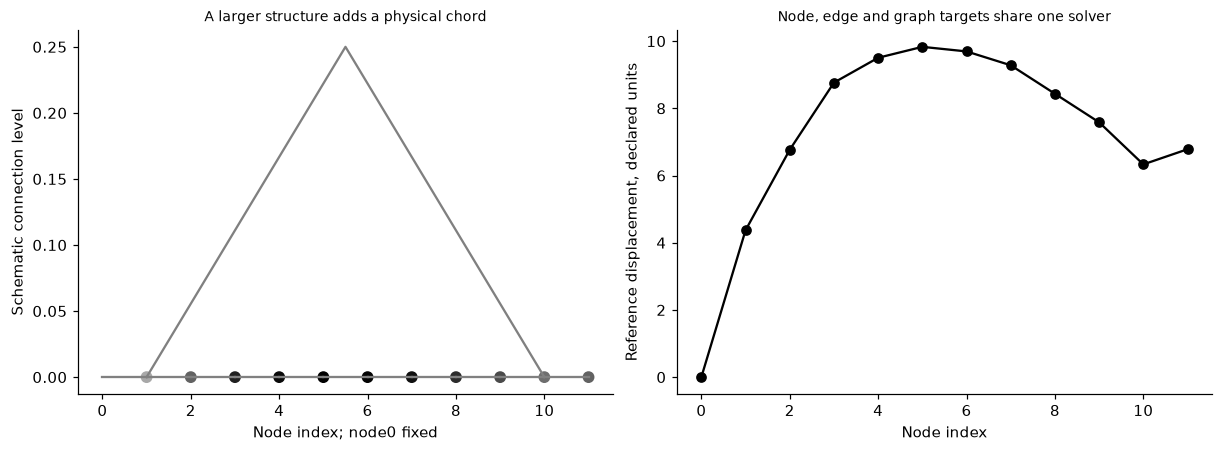

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
def structure(n,chord=False):
    edges=np.array([(j,j+1) for j in range(n-1)]+([(1,n-2)] if chord else []),dtype=int);k=rng.uniform(.8,1.8,len(edges));load=rng.uniform(.2,1.,n);load[0]=0;B=np.zeros((len(edges),n));B[np.arange(len(edges)),edges[:,0]]=-1;B[np.arange(len(edges)),edges[:,1]]=1;K=B.T@(k[:,None]*B);u=np.zeros(n);u[1:]=np.linalg.solve(K[1:,1:],load[1:]);force=k*(B@u);A=np.zeros((n,n));A[edges[:,0],edges[:,1]]=1;A+=A.T;incident=np.abs(B).T@k/np.maximum(np.abs(B).sum(0),1);x=np.c_[load,incident,np.linspace(0,1,n),np.arange(n)==0,np.full(n,n/8)];assert np.allclose(K[1:]@u,load[1:]) and np.linalg.eigvalsh(K[1:,1:]).min()>0;return {'x':x,'A':A/np.maximum(A.sum(1,keepdims=True),1),'edges':edges,'k':k,'u':u,'edge_force':force,'maximum':float(u.max()),'K':K,'load':load,'n':n,'chord':chord}
source=[structure(6+2*(j%2)) for j in range(40)];development=[structure(6+2*(j%2)) for j in range(10)];final_graphs=[structure(6+2*(j%2)) for j in range(10)]+[structure(12,True) for j in range(10)];assert not {id(g) for g in source}&{id(g) for g in development+final_graphs}
def collate(graphs):
    total=sum(g['n'] for g in graphs);A=np.zeros((total,total));pool=np.zeros((len(graphs),total));xs=[];ys=[];edges=[];ks=[];forces=[];offset=0
    for j,g in enumerate(graphs):
        n=g['n'];A[offset:offset+n,offset:offset+n]=g['A'];pool[j,offset:offset+n]=1/n;xs.append(g['x']);ys.append(g['u']);edges.append(g['edges']+offset);ks.append(g['k']);forces.append(g['edge_force']);offset+=n
    return tuple(torch.tensor(z) for z in [np.concatenate(xs),A,np.concatenate(ys),np.concatenate(edges),np.concatenate(ks),np.concatenate(forces),pool,np.array([g['maximum'] for g in graphs])])
training=collate(source);RESULTS.update(source_structures=40,development_structures=10,final_matched_chains=10,final_new_size_chord_structures=10,source_node_sizes=[6,8],challenge_node_size=12,graph_roles_disjoint=True,node_target='fixed-base spring displacement',edge_target='signed spring force',graph_target='maximum reference displacement',physical_reference_is_generated_not_field_truth=True);fig,axes=plt.subplots(1,2,figsize=(11,4));g=final_graphs[-1]
for a,b in g['edges']:
    axes[0].plot([a,b] if b-a==1 else [a,(a+b)/2,b],[0,0] if b-a==1 else [0,.25,0],color='.5')
axes[0].scatter(range(g['n']),np.zeros(g['n']),c=g['u'],cmap='Greys',s=45);axes[0].set(xlabel='Node index; node0 fixed',ylabel='Schematic connection level',title='A larger structure adds a physical chord');axes[1].plot(range(g['n']),g['u'],'o-',color='black');axes[1].set(xlabel='Node index',ylabel='Reference displacement, declared units',title='Node, edge and graph targets share one solver');plt.show()


## Train actual multitask message-passing variants and relational baselines
 One-hop and two-hop networks concatenate each node's own embedding with its row-mean neighbour embedding at each layer, using 24 hidden units. A softplus node head multiplied by the free-node mask enforces zero displacement at the support. A learned edge head receives both endpoint embeddings and edge stiffness; a graph head receives mean pooled embeddings. Train each for 250 full-source Adam updates on fixed normalized node/edge/graph squared losses. These original mean-aggregation networks are GraphSAGE-inspired, not full sampled GraphSAGE benchmark reproductions. Relational tabular controls use the same observable local features plus one/two-hop aggregates for boosted node regression, endpoint features for ridge edge regression and pooled summaries for ridge graph regression. Development node error alone chooses the GNN variant; final cases select nothing.


,model,regime,structures,node_RMSE,edge_RMSE,graph_absolute_error,equilibrium_residual_RMS
0,1-hop,matched chain,10,1.408110,0.290539,1.177283,1.975719
1,1-hop,new size + chord,10,5.452484,2.166804,9.164308,2.150799
2,2-hop,matched chain,10,3.322074,1.090898,3.025054,3.987301
3,2-hop,new size + chord,10,1.759328,2.396137,0.815915,3.161647
4,Relational baseline,matched chain,10,1.053558,0.335032,1.265904,1.436099
5,Relational baseline,new size + chord,10,2.931974,2.841229,16.577701,4.403234


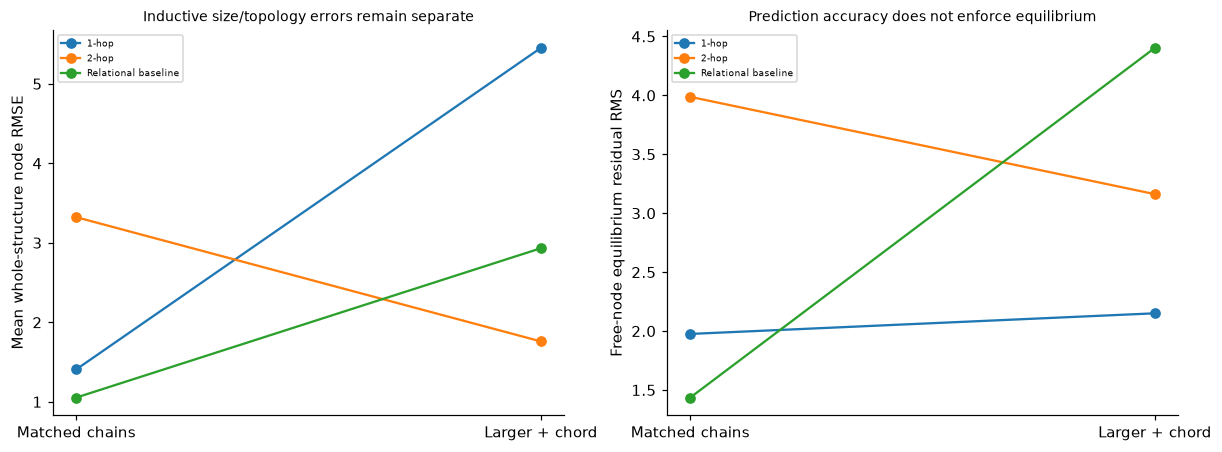

In [3]:
class GraphModel(nn.Module):
    def __init__(self,hops):
        super().__init__();self.layers=nn.ModuleList([nn.Linear(10,24)]+[nn.Linear(48,24) for _ in range(hops-1)]);self.node=nn.Linear(24,1);self.edge=nn.Sequential(nn.Linear(49,16),nn.Tanh(),nn.Linear(16,1));self.graph=nn.Linear(24,1)
    def forward(self,data):
        x,A,u,edge,k,force,pool,maximum=data;h=x
        for layer in self.layers:h=torch.tanh(layer(torch.cat([h,A@h],dim=1)))
        node=nn.functional.softplus(self.node(h)[:,0])*(1-x[:,3]);index=edge.long();ef=self.edge(torch.cat([h[index[:,0]],h[index[:,1]],k[:,None]],dim=1))[:,0];graph=nn.functional.softplus(self.graph(pool@h)[:,0]);return node,ef,graph
networks={}
for hops in [1,2]:
    model=GraphModel(hops);optimizer=torch.optim.Adam(model.parameters(),lr=.02)
    for _ in range(250):
        optimizer.zero_grad();node,edge,graph=model(training);loss=((node-training[2])/10).square().mean()+((edge-training[5])/4).square().mean()+((graph-training[7])/10).square().mean();loss.backward();optimizer.step()
    model.eval();networks[f'{hops}-hop']=model
def evaluate(model,graphs):
    rows=[]
    with torch.no_grad():
        for g in graphs:
            node,edge,graph=model(collate([g]));node=node.numpy();edge=edge.numpy();rows.append({'n':g['n'],'chord':g['chord'],'node_RMSE':float(np.sqrt(np.mean((node-g['u'])**2))),'edge_RMSE':float(np.sqrt(np.mean((edge-g['edge_force'])**2))),'graph_absolute_error':float(abs(graph.item()-g['maximum'])),'equilibrium_residual_RMS':float(np.sqrt(np.mean((g['K'][1:]@node-g['load'][1:])**2)))})
    return rows
dev={name:float(np.mean([r['node_RMSE'] for r in evaluate(m,development)])) for name,m in networks.items()};chosen=min(dev,key=dev.get)
def node_features(g):return np.c_[g['x'],g['A']@g['x'],g['A']@g['A']@g['x']]
def edge_features(g):return np.c_[g['x'][g['edges'][:,0]],g['x'][g['edges'][:,1]],g['k']]
def graph_features(g):return np.r_[g['x'].mean(0),g['n']]
node_base=HistGradientBoostingRegressor(max_iter=80,max_leaf_nodes=7,early_stopping=False,random_state=SEED).fit(np.concatenate([node_features(g) for g in source]),np.concatenate([g['u'] for g in source]));edge_base=Ridge(alpha=1).fit(np.concatenate([edge_features(g) for g in source]),np.concatenate([g['edge_force'] for g in source]));graph_base=Ridge(alpha=1).fit(np.array([graph_features(g) for g in source]),[g['maximum'] for g in source]);baseline=[]
for g in final_graphs:
    pred=node_base.predict(node_features(g));baseline.append({'n':g['n'],'chord':g['chord'],'node_RMSE':float(np.sqrt(np.mean((pred-g['u'])**2))),'edge_RMSE':float(np.sqrt(np.mean((edge_base.predict(edge_features(g))-g['edge_force'])**2))),'graph_absolute_error':float(abs(graph_base.predict(graph_features(g)[None])[0]-g['maximum'])),'equilibrium_residual_RMS':float(np.sqrt(np.mean((g['K'][1:]@pred-g['load'][1:])**2)))})
assessments={name:evaluate(m,final_graphs) for name,m in networks.items()};assessments['Relational baseline']=baseline;profiles=[]
for name,rows in assessments.items():
    for challenge in [False,True]:
        subset=[r for r in rows if r['chord']==challenge];profiles.append({'model':name,'regime':'new size + chord' if challenge else 'matched chain','structures':len(subset),**{key:float(np.mean([r[key] for r in subset])) for key in ['node_RMSE','edge_RMSE','graph_absolute_error','equilibrium_residual_RMS']}})
RESULTS.update(network_source_steps=250,development_node_RMSE=dev,development_selected_GNN=chosen,final_per_structure_assessments=assessments,final_regime_profiles=profiles,final_labels_select_architecture=False);display(pd.DataFrame(profiles));fig,axes=plt.subplots(1,2,figsize=(11,4))
for name in assessments:
    rows=[r for r in profiles if r['model']==name];axes[0].plot([0,1],[r['node_RMSE'] for r in rows],'o-',label=name);axes[1].plot([0,1],[r['equilibrium_residual_RMS'] for r in rows],'o-',label=name)
for ax in axes:ax.set(xticks=[0,1],xticklabels=['Matched chains','Larger + chord']);ax.legend(fontsize=6)
axes[0].set(ylabel='Mean whole-structure node RMSE',title='Inductive size/topology errors remain separate');axes[1].set(ylabel='Free-node equilibrium residual RMS',title='Prediction accuracy does not enforce equilibrium');plt.show()


## Check equivariance and explain a local dependence without granting a physical certificate
 Permute every node in one final graph, carrying features, adjacency, support flags, edge indices and targets together. Require the selected network's node outputs to permute, graph output to remain invariant and corresponding edge outputs to agree. Then mask only the extra chord in aggregation for a larger graph while retaining all other inputs; measure the change in its last-node prediction. This graph-message dependence diagnostic is not a physical intervention, because the incident-stiffness feature and reference system are not recomputed. Report independent node/edge/graph errors and equilibrium residuals for the selected model rather than calling a plausible drawing physically valid. A failure in the larger regime must remain visible even if matched-chain results look favourable.


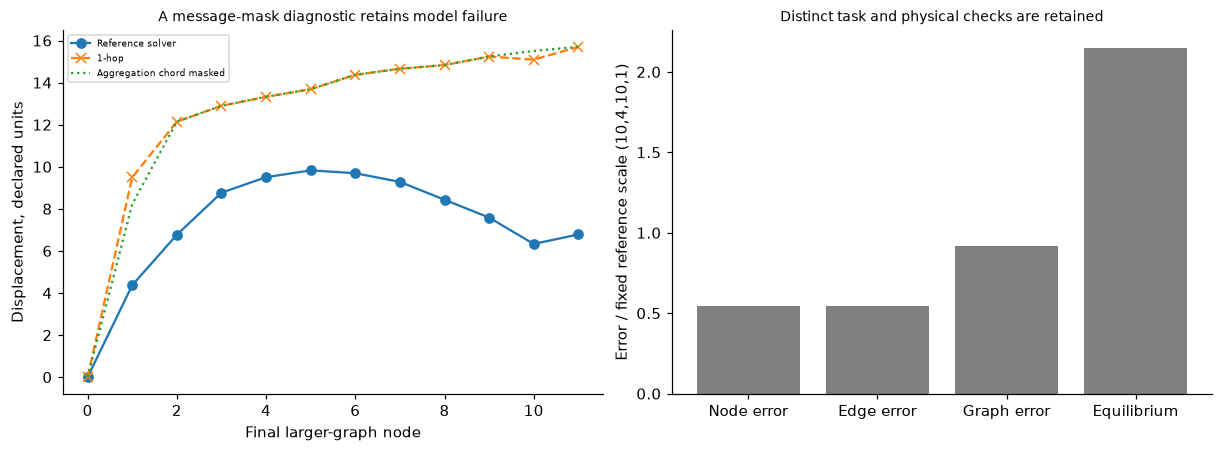

In [4]:
selected=networks[chosen];g=final_graphs[-1];perm=rng.permutation(g['n']);inverse=np.argsort(perm);permuted={**g,'x':g['x'][perm],'A':g['A'][perm][:,perm],'u':g['u'][perm],'edges':inverse[g['edges']],'K':g['K'][perm][:,perm],'load':g['load'][perm]}
with torch.no_grad():
    original=selected(collate([g]));reordered=selected(collate([permuted]));assert np.allclose(reordered[0].numpy(),original[0].numpy()[perm],atol=1e-10);assert np.allclose(reordered[1].numpy(),original[1].numpy(),atol=1e-10);assert np.allclose(reordered[2].numpy(),original[2].numpy(),atol=1e-10);A=g['A'].copy();a,b=g['edges'][-1];A[a,b]=A[b,a]=0;A=A/np.maximum(A.sum(1,keepdims=True),1e-12);masked={**g,'A':A};mask_prediction=selected(collate([masked]))[0].numpy();change=float(mask_prediction[-1]-original[0].numpy()[-1])
RESULTS.update(permutation_node_max_difference=float(np.max(abs(reordered[0].numpy()-original[0].numpy()[perm]))),permutation_edge_max_difference=float(np.max(abs(reordered[1].numpy()-original[1].numpy()))),permutation_graph_difference=float(abs(reordered[2].item()-original[2].item())),masked_chord_last_node_prediction_change=change,masked_chord_endpoint_prediction_change=float(mask_prediction[b]-original[0].numpy()[b]),edge_mask_is_not_physical_intervention=True,support_prediction_exact_zero=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(g['u'],'o-',label='Reference solver');axes[0].plot(original[0].numpy(),'x--',label=chosen);axes[0].plot(mask_prediction,':',label='Aggregation chord masked');axes[0].set(xlabel='Final larger-graph node',ylabel='Displacement, declared units',title='A message-mask diagnostic retains model failure');axes[0].legend(fontsize=6);axes[1].bar(['Node error','Edge error','Graph error','Equilibrium'],[next(r for r in profiles if r['model']==chosen and r['regime']=='new size + chord')[key] for key in ['node_RMSE','edge_RMSE','graph_absolute_error','equilibrium_residual_RMS']]/np.array([10.,4.,10.,1.]),color='.5');axes[1].set(ylabel='Error / fixed reference scale (10,4,10,1)',title='Distinct task and physical checks are retained');plt.show()


In [5]:
summary={'example_id':'code_227','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual positive-stiffness structural graph solves with node displacement edge force and graph maximum targets', 'trained one-hop and two-hop message-passing multitask networks versus relational tabular baselines', 'whole-structure development selection and unseen-size chord-topology assessment', 'actual permutation equivariance edge-mask diagnostic and retained equilibrium residual failures'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual positive-stiffness structural graph solves with node displacement edge force and graph maximum targets", "trained one-hop and two-hop message-passing multitask networks versus relational tabular baselines", "whole-structure development selection and unseen-size chord-topology assessment", "actual permutation equivariance edge-mask diagnostic and retained equilibrium residual failures"], "elapsed_seconds": 1.327, "example_id": "code_227", "hardware": "Darwin arm64 CPU", "resource_measurements": {}, "results": {"challenge_node_size": 12, "development_node_RMSE": {"1-hop": 1.7324624658924228, "2-hop": 3.3299452821238065}, "development_selected_GNN": "1-hop", "development_structures": 10, "edge_mask_is_not_physical_intervention": true, "edge_target": "signed spring force", "final_labels_select_architecture": false, "final_matched_chains": 10, "final_new_size_chord_structures": 10, "final_per_structure_assessments": {"1-hop": [{"chor